# Metadata Construction

First notebook in the data-object creation pipeline. Consolidates all sample-level metadata into a single parquet file consumed by all downstream notebooks.

## Description of the dataset

The SCI dataset spans **7 independent participating laboratories**, analyzing a total of 9 384-well plates across two instrument platforms (6 × Astral, 3 × timsTOF). Each plate consists of centrally prepared samples containing two cell lines (K562, HEK293T) and several blank and quality control samples. Additionally, each laboratory added their own site-specific QC and HeLa standards. For more information on the plate design, see the figure description below and the associated manuscript.

![Figure 1](../../Figures/Figure_1/overview_figure.png)

<details>
<summary>Figure 1 - Description</summary>

*Figure 1: Inter-laboratory workflow outline from centralized sample generation and data analysis to standardized LC MS/MS. (a) The centralized sample preparation was performed using the cellenONE cell isolation and picolitre-dispensing system. 384-well plate design include centralized QC samples (a quantitative three proteome-mix in 2 different ratios and a qualitative HeLa dilution at single-cell equivalents; n = 22 each per plate; and blanks n = 24 per plate), site-specific QCs (freshly prepared HeLa dilution and blanks; n = 24 and 28 per plate, respectively), sample preparation controls (processing control containing all buffers used during sample preparation, sorting control also contains the sorting liquid without a cell; n = 24 each per plate) and 2 different cell types (HEK293T and K562; n = 108 each per plate) that were lysed and digested in DDM with a Trypsin/Lys-C combination for 2 h at 45°C with continuous rehydration. The sealed plates were shipped to all participating laboratories, where they were centrifuged after thawing and prior to acquisition. (b) All samples were injected according to a uniform but randomized injection scheme, alternating QC and single-cell sample blocks on a Thermo Fisher Vanquish Neo with a PepMap 5-mm trap and an Ionopticks 8-cm analytical column. (c) Samples were acquired on either a Thermo Fisher Orbitrap Astral (n = 6) or a Bruker timsTOF Ultra2 (n = 3). Of note, except for one Astral using ABIRD, all other instruments were equipped with the FAIMS Pro interface. (d) Centralized data analysis was performed using six software tools on the quantitative QC mixes for selection of optimal downstream tool, including Spectronaut, DIA-NN, CHIMERYS, PEAKS, FragPipe and alphaDIA.*

</details>

## Source files for metadata harmonization

Metadata was captured from two independent sources:

| Source | Format | Content |
|---|---|---|
| **SDRF files** | `SDRF.xlsx` per lab | Acquisition metadata: sample identity, gradient time, plate number, injection timestamps |
| **cellenONE reports** | `Reordered_*_isolated.xls` per plate | Cell dispensing metadata: XY plate position, morphological measurements (diameter, elongation, circularity), QC flags, image paths |

This notebook merges both sources on plate position coordinates and applies a multi-step parsing and imputation pipeline to produce a single, analysis-ready metadata table.

## Imports

`SCI_read` handles raw file ingestion; `SCI_parse` handles column normalisation and imputation. Plot utilities draw the QC overview figures.

In [3]:
import matplotlib.pyplot as plt
import os
from pathlib import Path
import matplotlib.image as mpimg
import random
from glob import glob

from SCI_py.metadata import read as SCI_read
from SCI_py.metadata import parse as SCI_parse

from SCI_py.plot.metadata import plot_metadata_overview, plot_cell_qc_overview

## 0. Path Configuration

Set **`ZENODO_FOLDER`** to the folder you downloaded from [Zenodo](https://doi.org/10.5281/zenodo.21181080). Then the other paths should point correctly to:

- **`ROOT_SDRF_IN`** should point to the 'metadata' folder containing the SDRF files for each lab in subfolders. 
- **`ROOT_CELLENONE_IN`** should point towards the `CellenONE_Reports` folder containing the pictures and metadata for all (meta)data from the cellenONE instrument.

The output directory defaults to `Data/` relative to the notebook and can be overridden with the `SCI_DATA_DIR` environment variable. Alternatively, all data generated during the coming notebooks is readly availble in the zenodo folder as well at **`ZENODO_FOLDER/Data`**.

In [4]:
# Set the paths
ZENODO_FOLDER = "/public/conode53/sam/SCI_paper/Zenodo"

ROOT_SDRF_IN = os.path.join(ZENODO_FOLDER, 'metadata', 'SDRF')
ROOT_CELLENONE_IN = os.path.join(ZENODO_FOLDER, 'cellenONE')

# OUTPUT PATH
NOTEBOOK_DIR = Path().resolve()
ROOT_OUT      = NOTEBOOK_DIR / "../../Data"
ROOT_OUT      = ROOT_OUT.resolve()

# Allow user override via environment variable
ROOT_OUT = Path(os.environ.get("SCI_DATA_DIR", ROOT_OUT))

ROOT_OUT.mkdir(parents=True, exist_ok=True)
print(f"Output directory: {ROOT_OUT}")

Output directory: /home/sam/SCI/SCI/Data


## 1. Metadata File Construction

Four operations are chained to build the final metadata table. Each is described in detail below.

---

### 1.1 Read SDRF files — `SCI_read.read_SDRF`

One `SDRF.xlsx` file exists per lab, stored in a sub-directory named by plate ID (e.g. `Wyss_Astral_1/SDRF.xlsx`). All files are concatenated and the following transformations applied:

- **Sample name derivation** — each lab used a different filename convention, so a plate-specific converter function extracts the canonical sample name from `comment[data file]`. For example, Broad files with `_redo_` in the name require different splitting than IMP timsTOF files.
- **Plate number mapping** — `comment[Plate Number]` is populated from a lookup table (`LAB_TO_PLATENR`) because it is not reliably present in all SDRF files.
- **Well coordinate conversion** — `comment[X position]` is stored as a letter (A–P) in the SDRF; it is converted to a 1-based integer. A `WellName` column in `R{row}-C{col}` notation is computed from the (X, Y) pair, accounting for the cellenONE Y-axis convention: the instrument numbers rows from the bottom up, so Y = 1 is the physical bottom row, which maps to R24 in table notation (via 25 − Y).
- **Reinjection annotation** — two sites reinjected selected cells: Wyss reinjections are identified from a supplementary CSV (`CSI_Plate4run3.csv`); Broad reinjections are identified by the string `"redo"` in the filename. When both an original and a reinjection exist for the same cell, the reinjection is kept and the original dropped.
- **BYU source-name correction** — a known pipetting error caused BYU to swap `"Site specific QC"` and `"Site specific blanks"` well labels; these are silently corrected here.

---

### 1.2 Read cellenONE reports — `SCI_read.read_cellenONE`

The cellenONE dispenser writes one isolation report per plate × cell-type combination (`Reordered_*_isolated.xls`). These are scanned recursively, and for each file:

- Plate number is parsed from the parent directory name.
- Cell type (sample type) is parsed from the sub-directory name.
- An `image_path` column is constructed pointing to the per-cell brightfield image.
- Position columns (`XPos`, `YPos`) are renamed to the SDRF convention (`comment[X position]`, `comment[Y position]`) to enable the merge.

---

### 1.3 Merge and well-level QC annotations

The SDRF and cellenONE tables are joined on `comment[X position]`, `comment[Y position]`, and `comment[Plate Number]` (left join on SDRF). This attaches morphological measurements — **diameter**, **elongation**, **circularity** — and cell-dispensing QC flags to every acquisition row.

Manual per-well annotations from plate preparation notes are then applied as four boolean columns:

| Flag | Meaning |
|---|---|
| `Dying` | Cell showed morphological signs of death at dispensing |
| `Dividing` | Cell was caught mid-division (two nuclei or dumbbell shape) |
| `Doublet` | Two cells co-dispensed into one well |
| `CellInBlank` | A cell was accidentally dispensed into a designated blank well |

Annotations cover plates 2–10, 13, and 14. Plates 1, 11, and 12 have only free-text notes (recorded in `PLATE_NOTES`).

Note that cellenONE-based annotation is unavailable for quantitative QC samples, blanks and site-specific QC and blank samples.

---

### 1.4 Metadata parsing pipeline — `SCI_parse.parse_metadata_columns`

An 8-step pipeline is applied to the merged table:

1. **Sample name normalisation** — convert to lowercase for consistent joining with search results.

2. **Temporal column parsing** — three raw datetime strings (`comment[plate arrival]`, `comment[Gradient time]` (stores the injection timestamp despite the column name), `comment[thawing timepoint]`) are each split into three derived columns:
   - `_date` — date floored to midnight
   - `_time` — decimal hours (e.g. 14.5 = 14:30:00)
   - `_datetime` — full timestamp

3. **Derived identifier columns**
   - `instrument_type` — extracted from the plate ID (e.g. `"Astral"`, `"timsTOF"`)
   - `sample_id` — globally unique key: `sample_name|plate_id`
   - `plate_idx` — anonymised lab label used in figures (e.g. `"Astral_1"`, `"timsTOF_2"`)

4. **Source name normalisation** — internal dispensing labels (`"Cell A"`, `"Cell B"`) are mapped to the biological cell line names (`"K562"`, `"HEK293T"`).

5. **Injection order** — a normalised injection order in [0, 1] is computed within each plate from `comment[Gradient time]_datetime`. Astral_6 had missing datetime annotations, so the day was inferred from 'thawing timepoint', which will not be entirely accurate and the injection times were copied from another plate analysed in the same lab. The order of injection is fixed, so this will not be an issue.

6. **Missing value imputation** — three strategies applied in sequence:
   - *Scalar sentinels* — numeric fields (morphology measurements, plate coordinates) are filled with `-1`; SDRF controlled-vocabulary text fields with `"not applicable"` or `"not available"`.
   - *Source-name lookups* — SDRF characteristic columns (organism, organism part, cell type, disease, cell line) are fully overwritten from lookup tables keyed on `source name`, ensuring consistency across all labs.
   - *Plate-specific imputation* — `KI_Astral_2` lacks gradient time data; dates are copied from the thawing timepoint and gradient times are matched by sample name from the paired `KI_Astral_1` plate, with datetimes reconstructed from the imputed components.

7. **Type enforcement** — X/Y positions cast to `int`; date/time columns to `str`; QC flag columns (`Reinjection`, `Doublet`, `Dividing`, `Dying`, `CellInBlank`) to `bool`.

8. **Duplicate column removal** — some SDRF files introduce a spurious `comment[plate arrival].1` column during concatenation; it is dropped here.

In [5]:
# Read the SDRF files and parse some columns
sdrf = SCI_read.read_SDRF(
    ROOT_SDRF_IN
)
# Read the cellenONE metadata files
isolated_df = SCI_read.read_cellenONE(ROOT_CELLENONE_IN)

# Merge the two metadata sources
metadata = sdrf.merge(
    isolated_df,
    on=['comment[X position]', 'comment[Y position]', 'comment[Plate Number]'],
    how='left'
)

# Add annotations from the plate preparation documentation
metadata = SCI_read.add_docx_annotations(metadata)

# Parse
metadata = SCI_parse.parse_metadata_columns(metadata)

/public/conode53/sam/SCI_paper/Zenodo/cellenONE/Plate_13_CHRISTINE/K562_plate13_20250929_121702_957.Run/Reordered_20250929_12170429_K562_plate13_isolated.xls
/public/conode53/sam/SCI_paper/Zenodo/cellenONE/Plate_13_CHRISTINE/HEK_plate13_2_20250929_113849_711.Run/Reordered_20250929_11385129_HEK_plate13_2_isolated.xls
/public/conode53/sam/SCI_paper/Zenodo/cellenONE/Plate_13_CHRISTINE/NEG_plate13_20250929_124914_132.Run/Reordered_20250929_12491629_K562_NEG_plate13_isolated.xls
/public/conode53/sam/SCI_paper/Zenodo/cellenONE/Plate_05_KARL/K562_plate5_20250911_113403_243.Run/Reordered_20250911_11340511_K562_plate5_isolated.xls
/public/conode53/sam/SCI_paper/Zenodo/cellenONE/Plate_05_KARL/NEG_plate5_20250911_120410_730.Run/Reordered_20250911_12041211_NEG_plate5_isolated.xls
/public/conode53/sam/SCI_paper/Zenodo/cellenONE/Plate_05_KARL/HEK_plate5_20250911_105722_617.Run/Reordered_20250911_10572411_HEK_plate5_isolated.xls
/public/conode53/sam/SCI_paper/Zenodo/cellenONE/Plate_10_AKOS/NEG_plate1

/home/sam/SCI/SCI/SCI_py/SCI_py/metadata/parse.py:233: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby("plate_id", group_keys=False).apply(_plate_order)


## 2. Visualisation

Two QC figures are generated to verify the metadata before saving:

- **`plot_metadata_overview`** — shows sample counts per lab and condition, QC flag counts per plate, counts of plates being acquired by specific instrument platforms, and plots showing acquisition order and plate arrivals. Useful for spotting missing plates or mislabelled conditions.
- **`plot_cell_qc_overview`** — shows distributions of morphological measurements (diameter, elongation, circularity), overview figure of the location of samples for each condition on the plates, and acquisition order and days for each plate.

/home/sam/SCI/SCI/SCI_py/SCI_py/plot/metadata.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(plate_order, rotation=45, ha='right')
/home/sam/SCI/SCI/SCI_py/SCI_py/plot/metadata.py:87: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(instrument_counts.index, rotation=35, ha='right')
/home/sam/SCI/SCI/SCI_py/SCI_py/plot/metadata.py:139: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


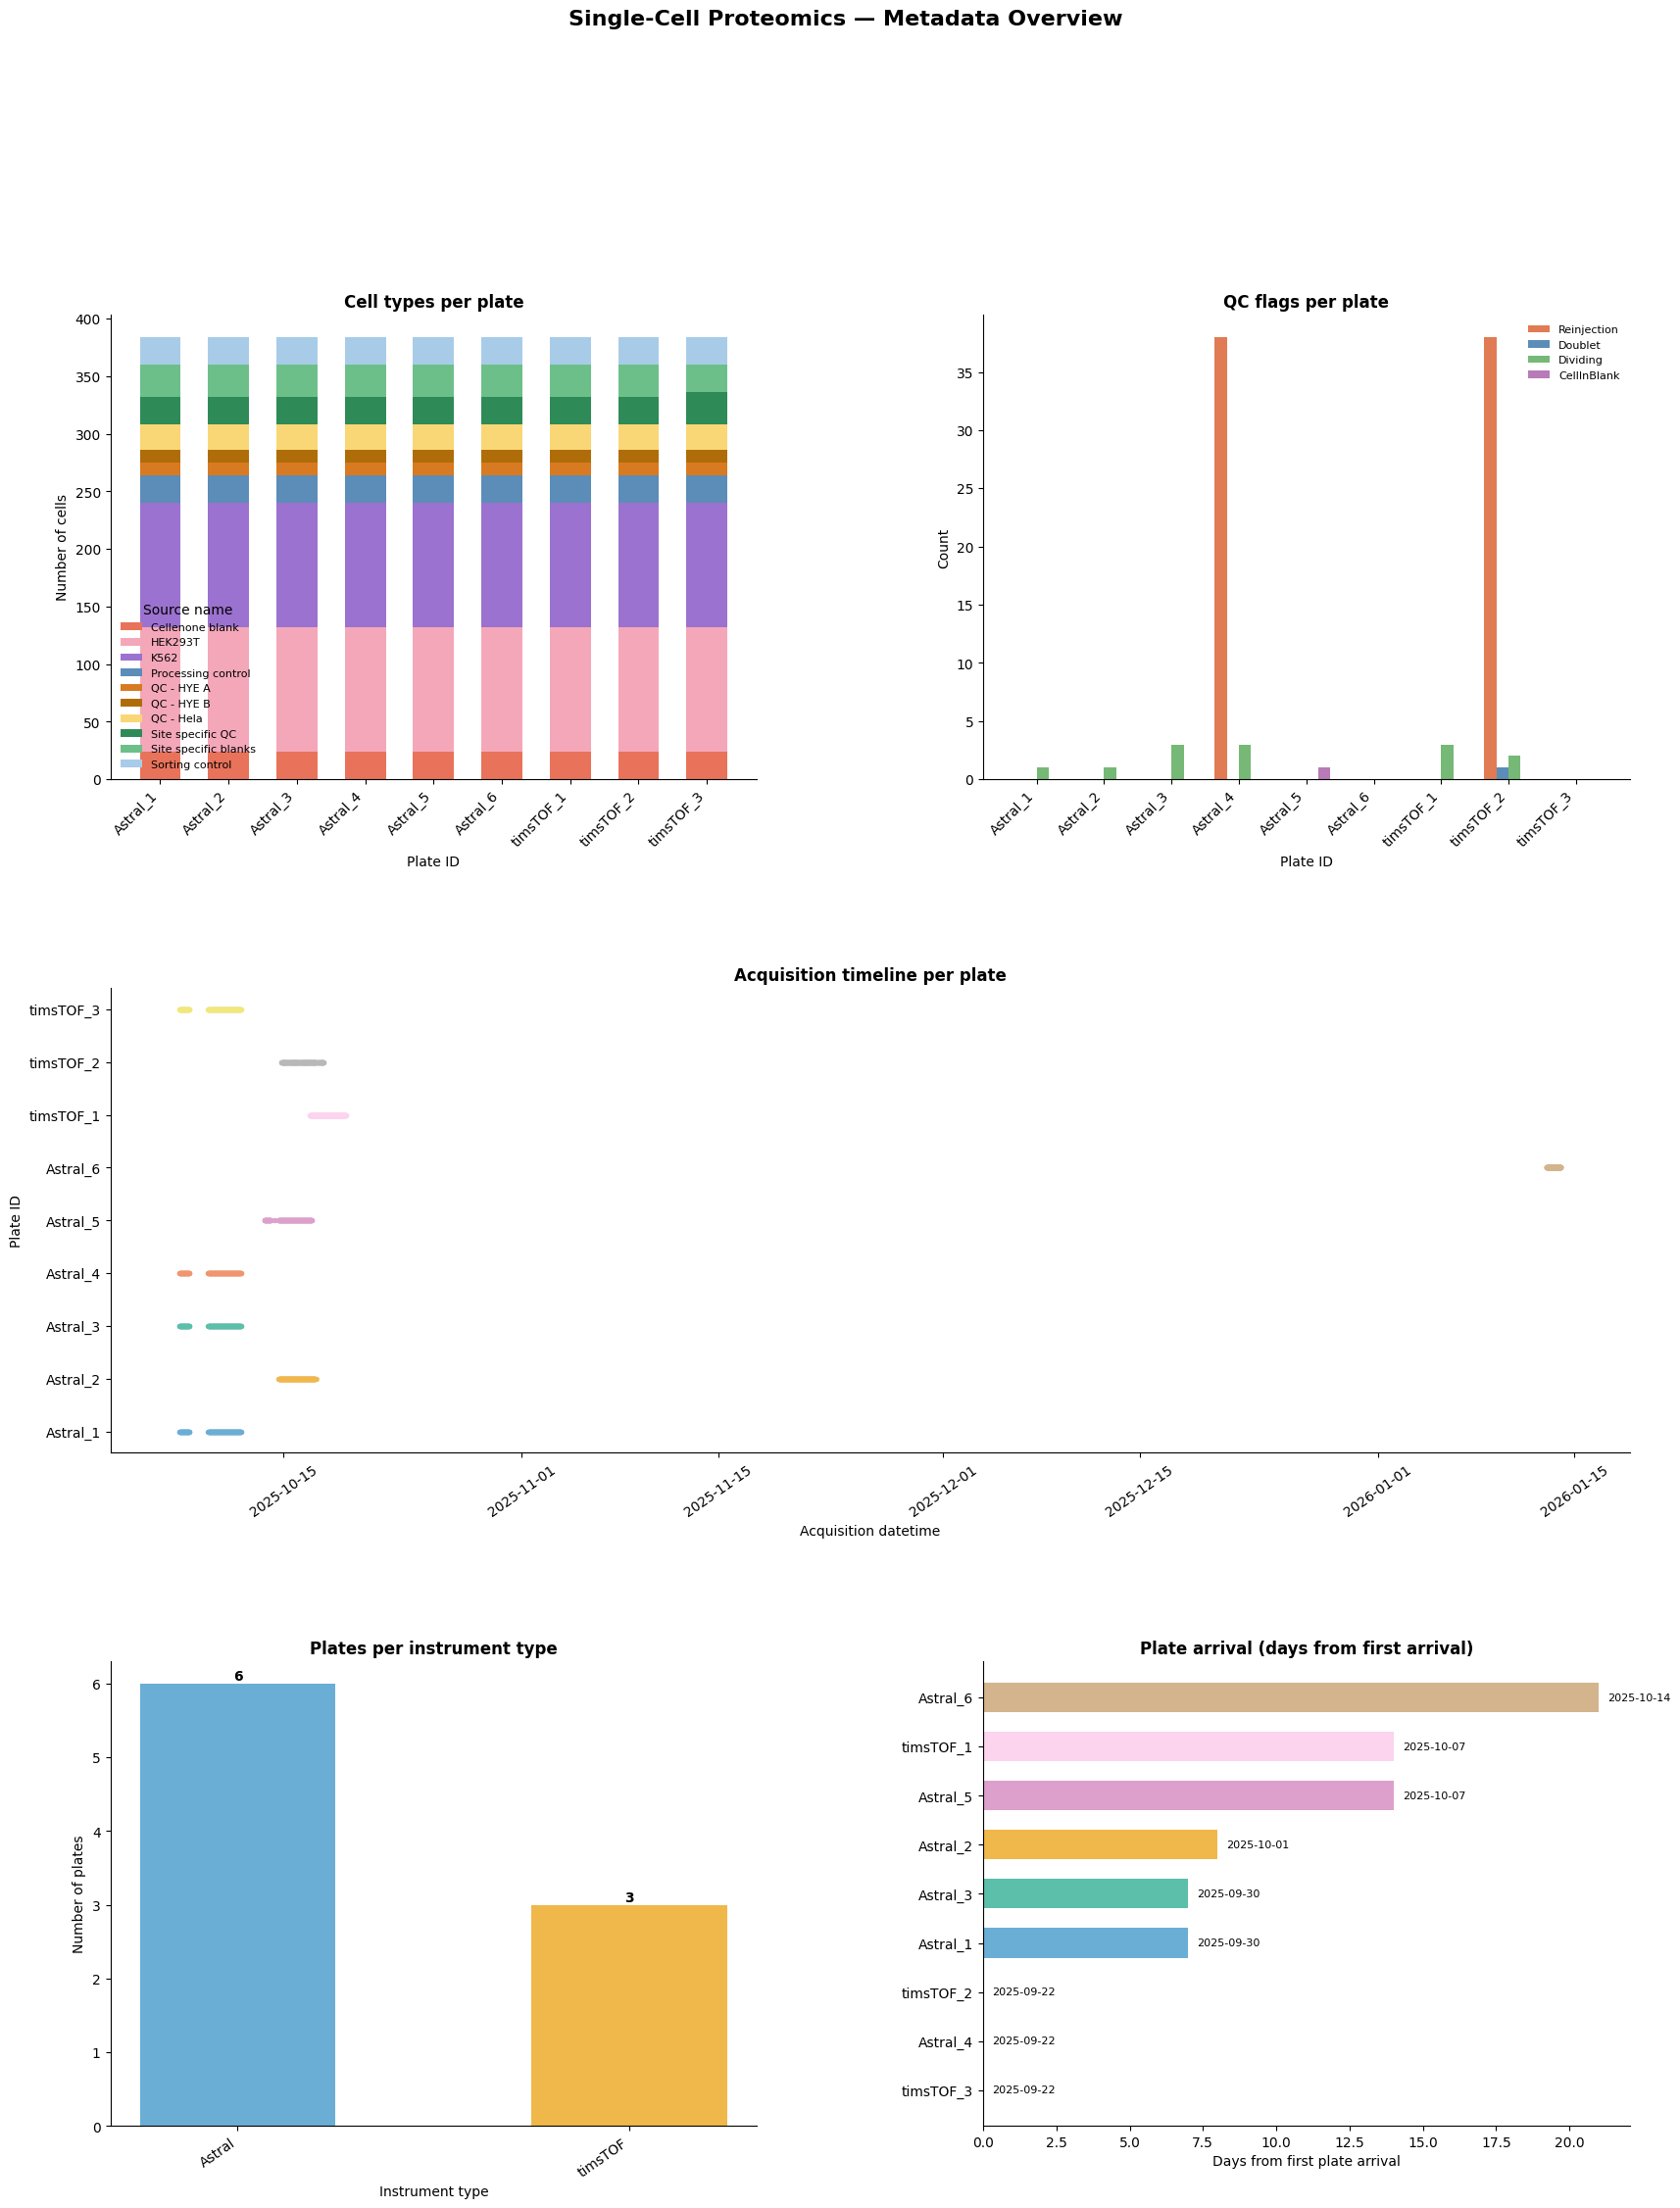

In [6]:
fig = plot_metadata_overview(
    metadata,
    save_path=False
)

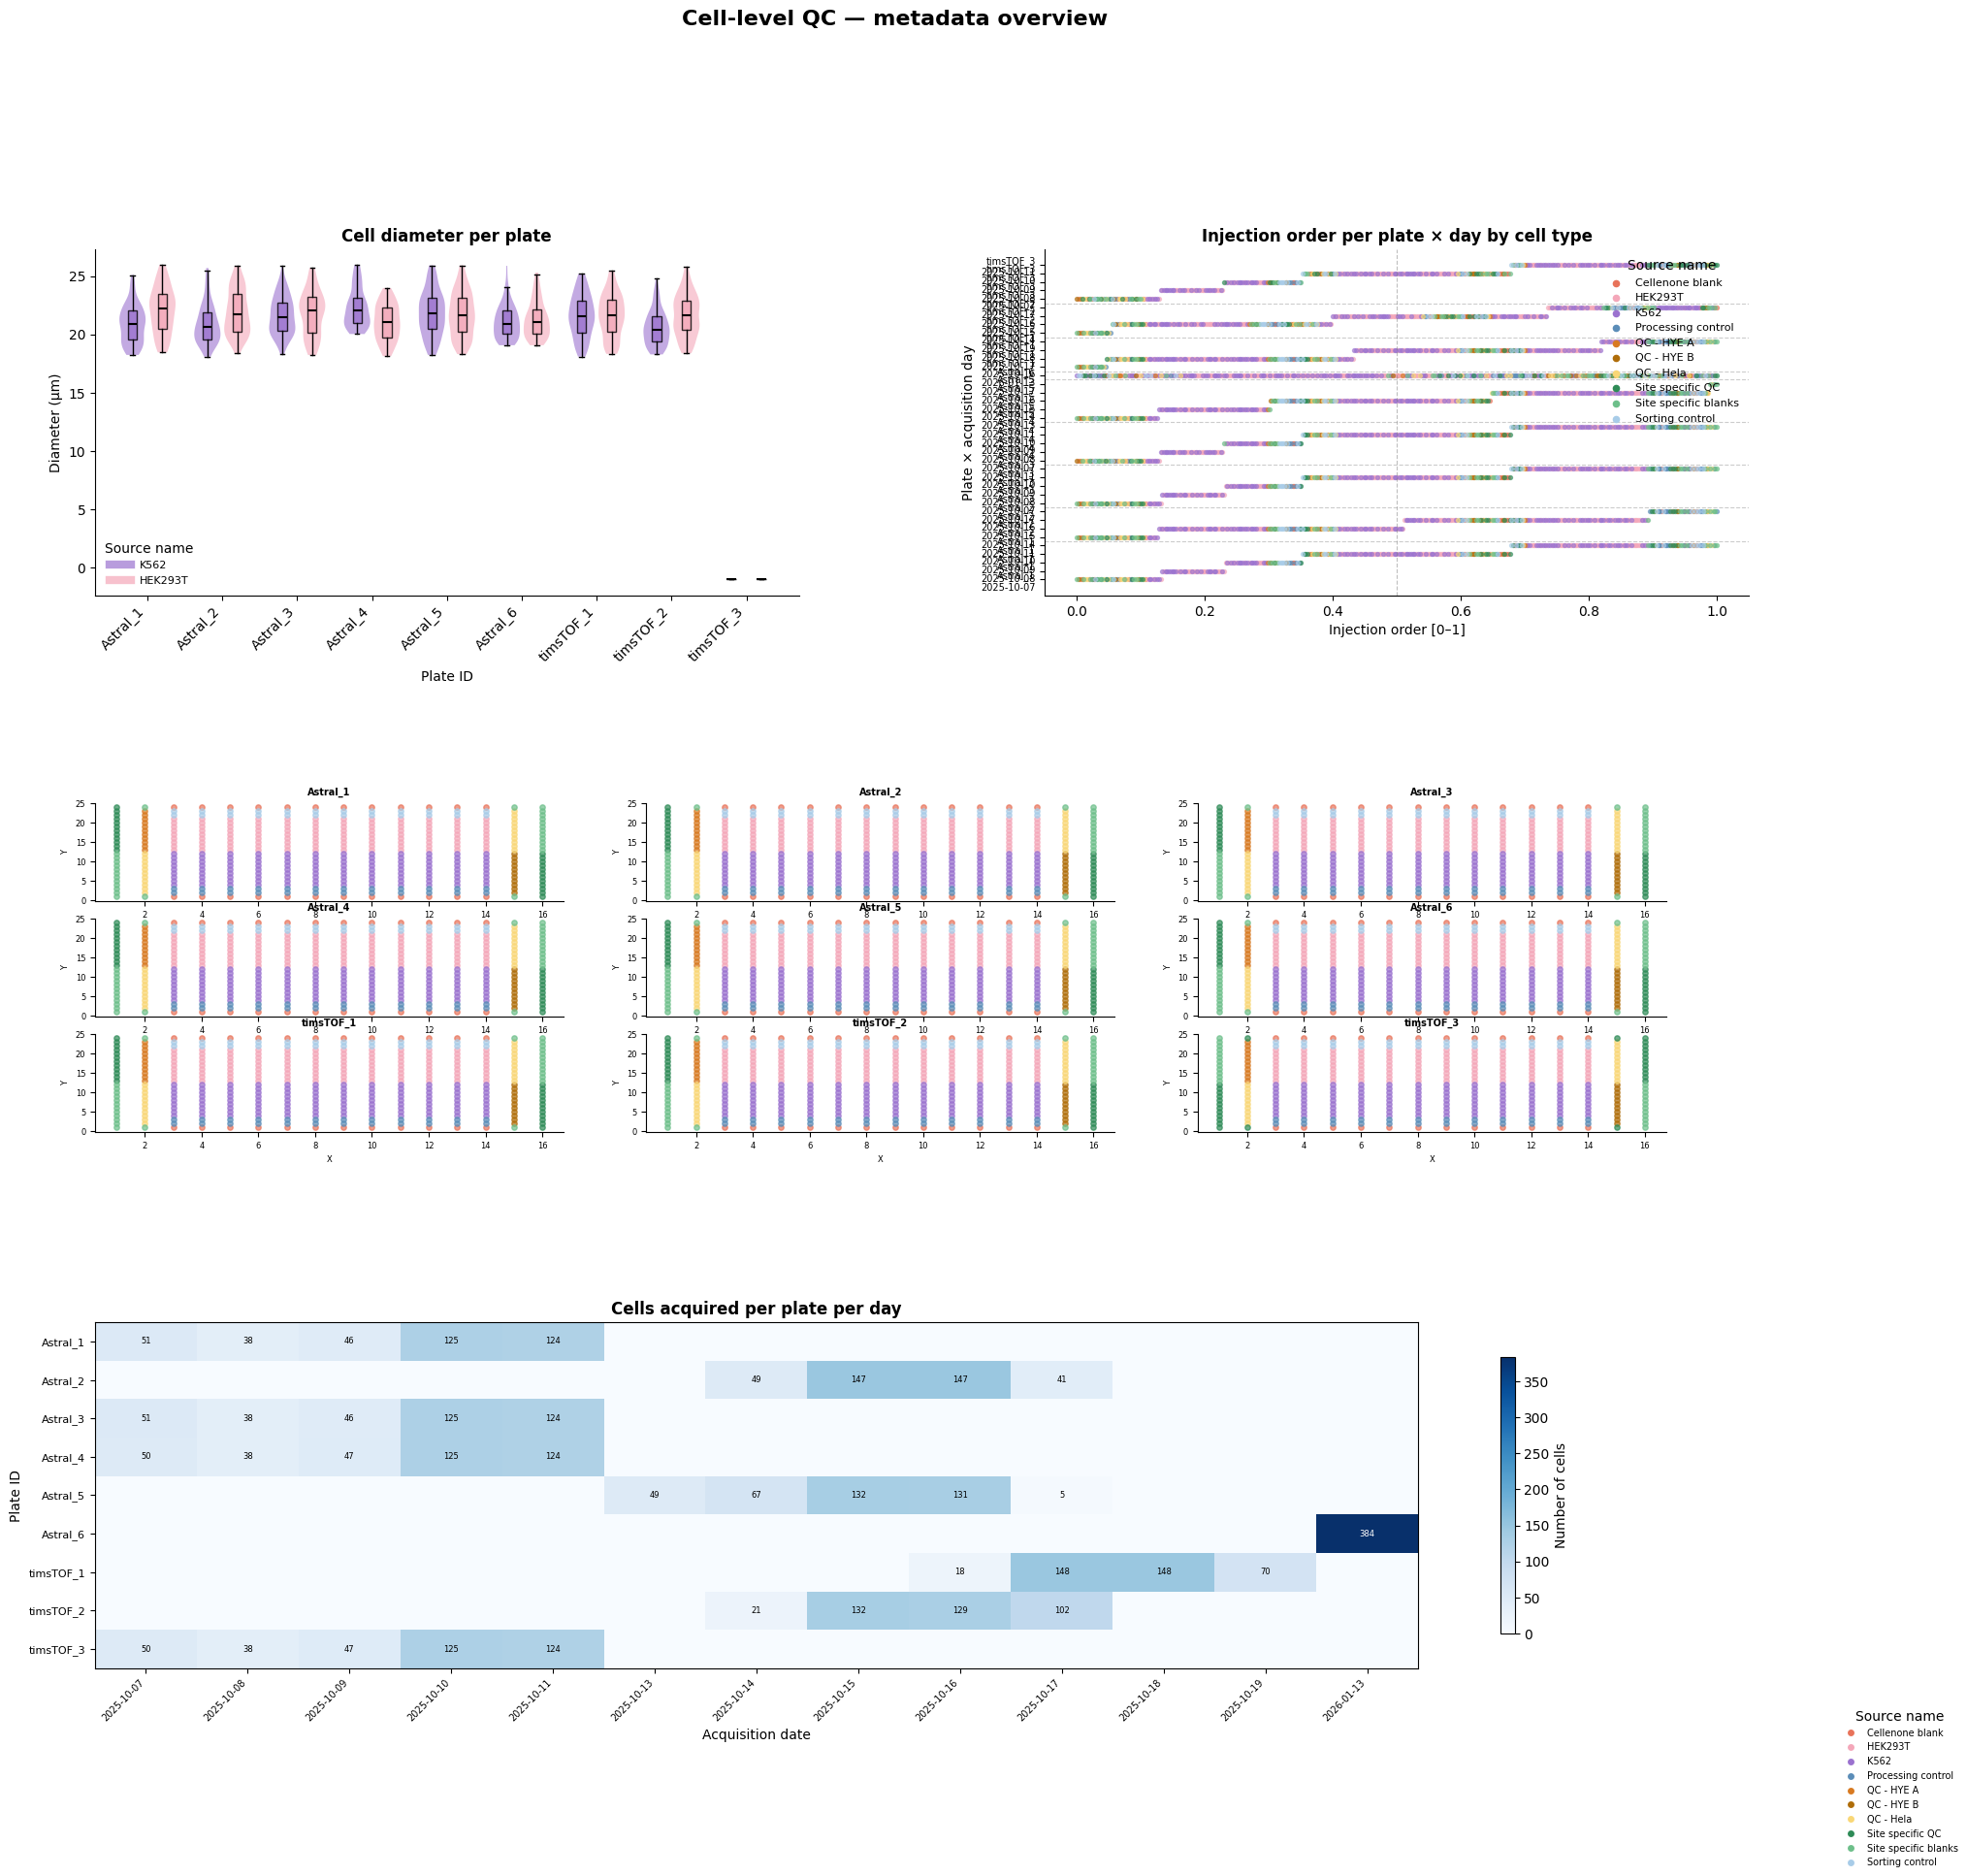

In [7]:
fig = plot_cell_qc_overview(
    metadata, 
    save_path=False
)

## 3. Images of Dividing/Doublet/CellInBlank dispensing

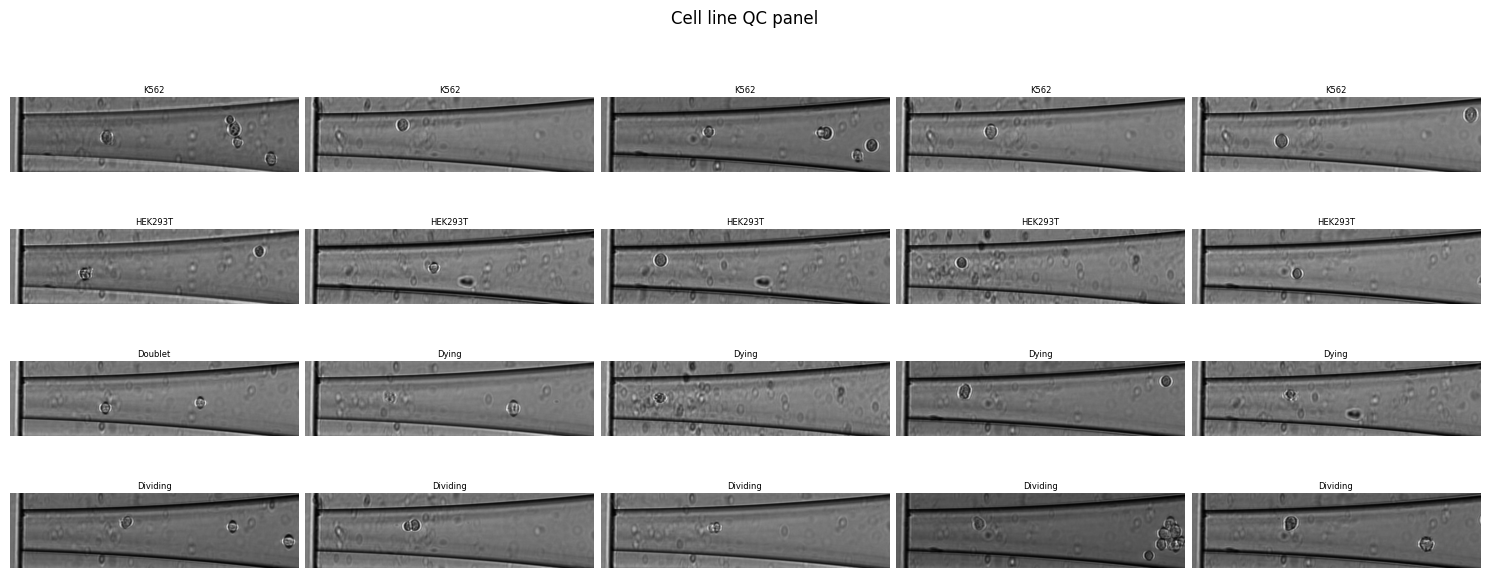

In [8]:
def valid_paths(paths):
    return [
        p for p in paths
        if str(p).lower() not in ("not applicable", "nan", "none", "")
        and Path(p).exists()
    ]

paths_K562 = metadata.loc[
    (~metadata['Doublet']) &
    (~metadata['Dying']) &
    (metadata['source name'] == 'K562'),
    'image_path'
]
paths_HEK293T = metadata.loc[
    (~metadata['Doublet']) &
    (~metadata['Dying']) &
    (metadata['source name'] == 'HEK293T'),
    'image_path'
]
paths_doublet = metadata.loc[
    metadata['Doublet'],
    'image_path'
]
paths_dying = metadata.loc[
    metadata['Dying'],
    'image_path'
]
paths_dividing = metadata.loc[
    metadata['Dividing'],
    'image_path'
]
paths_cellinblank = metadata.loc[
    metadata['CellInBlank'],
    'image_path'
]

k562_sample    = random.sample(valid_paths(paths_K562),    5)
hek_sample     = random.sample(valid_paths(paths_HEK293T), 5)
doublet_sample = valid_paths(paths_doublet)[:1]
dying_sample   = random.sample(valid_paths(paths_dying),   4)
dividing_sample = random.sample(valid_paths(paths_dividing), 5)

panels = [
    ("K562",     k562_sample),
    ("HEK293T",  hek_sample),
    ("Doublet / Dying", doublet_sample + dying_sample),
    ("Dividing", dividing_sample)
]

ncols = 5
nrows = len(panels)

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 6))

for row, (label, paths) in enumerate(panels):
    for col in range(ncols):
        ax = axes[row, col]
        if col < len(paths):
            if row==2:
                if col==0:
                    label='Doublet'
                else:
                    label='Dying'
            ax.imshow(mpimg.imread(paths[col]), cmap='gray')
            ax.set_title(label, fontsize=6, pad=3)
        else:
            ax.set_visible(False)
        ax.axis("off")

fig.suptitle("Cell line QC panel", fontsize=12, y=1.01)
fig.tight_layout(h_pad=2, w_pad=0.5)
plt.show()

As is clear from the images, there are more doublets than annotated, with some sampled images even containing 3 cells. Certainly, more cells than annotated are in a 'dying'/'dividing' state as pictures for K562 and HEK293T can be found of which the cell morphologies resemble the morphology from the annotated dying/dividing cells. Also, the dividing cells sometimes resembles a bit the dying cell morphology. In short, the annotation is not always very clear-cut and should be taken into account when doing downstream analysis. Since the paths are annotated in the metadata file, these images can be viewed directly during the analysis for outlier detection.

In future projects, one can envision to encode cell morphology directly from the images and integrate these encodings in downstream analyses.

## 4. Save

Write the completed metadata table to `Data/metadata/metadata.parquet`. Parquet is used rather than CSV to preserve column dtypes (bool flags, timestamps).

In [10]:
METADATA_OUT

'/home/sam/SCI/SCI/Data/metadata'

In [9]:
METADATA_OUT = os.path.join(ROOT_OUT, 'metadata')
Path(METADATA_OUT).mkdir(parents=True, exist_ok=True)

metadata.to_parquet(
    os.path.join(
        METADATA_OUT,
        'metadata.parquet'
    )
)